# Hito 3 — Análisis exploratorio de características acústicas

**Objetivo:** revisar los resultados generados por el pipeline, sin modificar los WAV ni los metadatos del Hito 2.

**Orden recomendado:** primero ejecutar desde PowerShell la verificación y la muestra (`--limit 60`), y luego este notebook. Si existe `src/data/features/features.csv`, revisará el resultado oficial; si no, revisará la muestra guardada en `experiments/results/hito3/preview/data/`.

El PCA fue ajustado **únicamente con entrenamiento**. Este notebook muestra solamente los clips de entrenamiento para no analizar prematuramente el conjunto test.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Permite abrir el notebook desde la raíz o desde notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Abre Jupyter desde Proyecto-1-MIAA/"

full = ROOT / "src" / "data" / "features" / "features.csv"
if full.exists():
    data_file = full
    results = ROOT / "experiments" / "results" / "hito3"
else:
    data_file = ROOT / "experiments" / "results" / "hito3" / "preview" / "data" / "features.csv"
    results = ROOT / "experiments" / "results" / "hito3" / "preview"
assert data_file.is_file(), "Ejecuta primero el pipeline del Hito 3 (--limit 60)"

df = pd.read_csv(data_file)
columns = json.loads((results / "feature_columns.json").read_text(encoding="utf-8"))
summary = json.loads((results / "hito3_summary.json").read_text(encoding="utf-8"))
print("Archivo:", data_file)
print("Estado:", summary["status"])
print("Tamaño:", df.shape)
print("Features:", len(columns))
print(df["partition"].value_counts())
df[["clip_id", "primary_label", "split", "partition"]].head()

Archivo: /Users/veroserna1/Github repositories/Proyecto 1 MIAA/src/data/features/features.csv
Estado: FULL_EXECUTION
Tamaño: (20748, 120)
Features: 90
partition
train    14296
val       3597
test      2855
Name: count, dtype: int64


,clip_id,primary_label,split,partition
0,bugtan_XC112883_c00,bugtan,fold4,val
1,bugtan_XC118988_c00,bugtan,fold4,val
2,bugtan_XC118988_c01,bugtan,fold4,val
3,bugtan_XC119223_c00,bugtan,fold4,val
4,bugtan_XC119223_c01,bugtan,fold4,val


## 1. Validaciones básicas

La tabla debe conservar una fila por clip, identificadores únicos, columnas acústicas finitas y exactamente 90 características. El escalador aprendió solamente de los clips `train`.

In [2]:
X = df[columns]
assert len(columns) == 90
assert df["clip_id"].is_unique
assert X.notna().all().all()
assert np.isfinite(X.to_numpy(dtype=float)).all()
print("Todas las validaciones numéricas pasaron")
print("Muestras que ajustaron scaler:", summary["n_samples_seen_scaler"])
print("Muestras que ajustaron PCA:", summary["n_samples_seen_pca"])
print("Varianza explicada PC1-PC3:", summary["pca_explained_variance_ratio"])
train = df[df["partition"] == "train"]
print("Media absoluta máxima en train:", train[columns].mean().abs().max())

Todas las validaciones numéricas pasaron
Muestras que ajustaron scaler: 14296
Muestras que ajustaron PCA: 14296
Varianza explicada PC1-PC3: [0.25944316387176514, 0.059432294219732285, 0.04778444766998291]
Media absoluta máxima en train: 1.7746478308789062e-07


## 2. Proyección PCA 2D, solo entrenamiento

Cada punto es un clip. Los colores representan la especie principal para facilitar la lectura, pero las etiquetas originales pueden ser multietiqueta. PCA no es un clasificador.

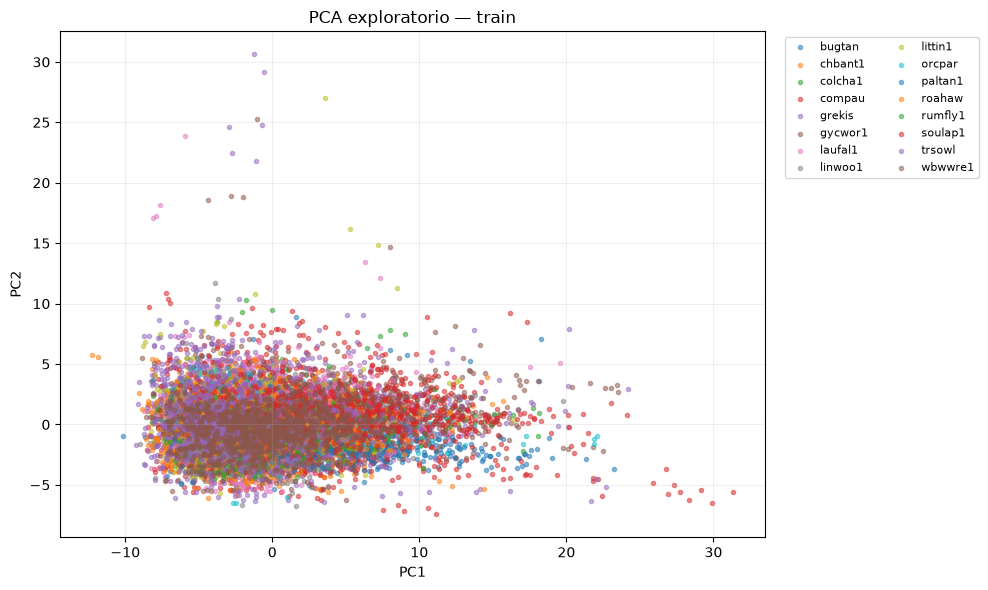

In [3]:
pca = pd.read_csv(results / "pca_scores_train_val.csv")
plot_df = pca[pca["partition"] == "train"]
fig, ax = plt.subplots(figsize=(10, 6))
for sp, sub in plot_df.groupby("primary_label"):
    ax.scatter(sub["PC1"], sub["PC2"], s=9, alpha=.5, label=sp)
ax.set(title="PCA exploratorio — train", xlabel="PC1", ylabel="PC2")
ax.legend(fontsize=8, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

Como se observa en la grafica tenemos una nube central” densa con muchos puntos mezclados entre colores
algunos puntos aislados, pero no un patrón claro por especie.
Eso quiere decir:

* Las primeras dos componentes no capturan suficientemente la separación entre especies
* La variabilidad acústica dentro de cada especie es grande
* Varias especies tienen sonidos similares en esas características
* también puede haber ruido, calidad variable, autor, grabación, etc., que diluye la separación

## 3. Revisión del informe del pipeline

El informe conserva configuración, conteos, versiones de dependencias y la comprobación de que no se utilizó test para ajustar StandardScaler ni PCA. El `features.csv` generado incluye metadatos, pero **solo las 90 columnas listadas en `feature_columns.json`** deberán utilizarse como predictoras.

In [4]:
print("Clips procesados:", summary["n_processed"])
print("Clips en manifiesto:", summary["n_manifest"])
print("Features:", summary["n_features"])
print("Uso de test en fit:", summary["test_used_to_fit_transformations"])
print("Configuración:")
print(json.dumps(summary["acoustic_configuration"], indent=2, ensure_ascii=False))
assert summary["test_used_to_fit_transformations"] is False

Clips procesados: 20748
Clips en manifiesto: 20748
Features: 90
Uso de test en fit: False
Configuración:
{
  "sr": 32000,
  "duration_s": 5,
  "n_mfcc": 13,
  "n_mels": 64,
  "n_fft": 1024,
  "hop_length": 320,
  "fmin": 150,
  "fmax": 14000,
  "delta_width": 9,
  "roll_percent": 0.85,
  "min_rms": 1e-07,
  "min_valid_spectral_ratio": 0.1
}
